# NOAA GML MBL CO2 Zonal Reference

Derived from atmospheric carbon dioxide mixing ratios
from the NOAA GML Carbon Cycle Cooperative Global Air
Sampling Network.

National Oceanic and Atmospheric Administration (NOAA)
Global Monitoring Laboratory (GML)
Carbon Cycle Greenhouse Gases (CCGG)

Reference produced by gml.noaa.gov/ccgg/GHGreference/.

# 0. Imports & Setup

Libraries

In [1]:
import os
import numpy as np
import pandas as pd
import xarray as xr
import matplotlib.pyplot as plt

Paths

In [ ]:
from utils.paths import NOAA_MBL_FILE, NOAA_MBL_ZARR, ensure_project_dirs, print_paths

ensure_project_dirs()

# download:  https://gml.noaa.gov/ccgg/mbl/data.php
file_in = NOAA_MBL_FILE
store_out = NOAA_MBL_ZARR

print_paths(
    ("NOAA MBL input", NOAA_MBL_FILE),
    ("NOAA MBL Zarr", NOAA_MBL_ZARR)
)

Output Zarr store: /home/efs25/GitHub/irp-efs25/data/processed/satellite/noaa_gml_mbl_1x1_monthly.zarr


## 1. Load and Inspect

Set global vars

In [ ]:
# Grid
lat_start = -89.5
lat_end = 89.5
lat_step = 1.0

# Longitude: -179.5 to +179.5
lon_start = -179.5
lon_end = 179.5
lon_step = 1.0

# Chunking for Zarr
time_chunk = 12
lat_chunk = 90
lon_chunk = 180

Load NOAA MBL text file

In [ ]:
# ignore first few lines of comments

raw = pd.read_csv(
    file_in,
    comment="#",
    sep=r"\s+",
    header=None,
)

print("Raw shape:", raw.shape)
print(raw.head())

Raw shape: (1537, 83)
            0        1      2        3      4        5      6        7   \
0  1993.000000  354.975  0.077  354.960  0.073  354.940  0.100  354.912   
1  1993.020833  354.882  0.093  354.858  0.086  354.827  0.106  354.790   
2  1993.041667  354.784  0.111  354.754  0.102  354.716  0.116  354.675   
3  1993.062500  354.685  0.129  354.653  0.117  354.617  0.126  354.582   
4  1993.083333  354.590  0.141  354.560  0.129  354.527  0.132  354.498   

      8        9   ...       73     74       75     76       77     78  \
0  0.156  354.877  ...  360.512  0.456  360.800  0.399  361.074  0.350   
1  0.157  354.752  ...  360.755  0.470  361.029  0.412  361.295  0.363   
2  0.163  354.637  ...  360.955  0.477  361.191  0.417  361.425  0.360   
3  0.168  354.554  ...  361.118  0.478  361.308  0.414  361.498  0.344   
4  0.169  354.480  ...  361.258  0.471  361.409  0.404  361.561  0.323   

        79     80       81     82  
0  361.326  0.343  361.548  0.372  
1  361.546

Source coordinates

In [ ]:
n_source_lat = 41

sin_lat = np.linspace(-1.0, 1.0, n_source_lat)

source_lat = np.degrees(
    np.arcsin(sin_lat)
)

print("Number of source latitudes:", len(source_lat))
print("Source latitude range:", source_lat.min(), "to", source_lat.max())

Number of source latitudes: 41
Source latitude range: -90.0 to 90.0


Good!

Check file structure

In [ ]:
expected_columns = 1 + 2 * n_source_lat

assert raw.shape[1] == expected_columns, (
    f"Expected {expected_columns} columns "
    f"but found {raw.shape[1]}"
)

# First column is decimal year
decimal_year = raw.iloc[:, 0].values

# Remaining columns alternate:
# CO2, uncertainty, CO2, uncertainty, ...

co2_raw = raw.iloc[:, 1::2].copy()
uncertainty_raw = raw.iloc[:, 2::2].copy()

assert co2_raw.shape[1] == n_source_lat
assert uncertainty_raw.shape[1] == n_source_lat

print("CO2 shape:", co2_raw.shape)
print("Uncertainty shape:", uncertainty_raw.shape)

CO2 shape: (1537, 41)
Uncertainty shape: (1537, 41)


## 2. Processing

### Convert decimal-year timestamps to actual dates

In [ ]:
def decimal_year_to_datetime(decimal_year):
    """
    Convert decimal-year timestamps to actual datetimes

    The fractional part represents the fraction of the
    calendar year elapsed.
    """
    year = np.floor(decimal_year).astype(int)
    fraction = decimal_year - year

    dates = []

    for y, f in zip(year, fraction):
        start = pd.Timestamp(year=y, month=1, day=1)
        end = pd.Timestamp(year=y + 1, month=1, day=1)

        dates.append(
            start + (end - start) * f
        )

    return pd.DatetimeIndex(dates)

In [ ]:
time = decimal_year_to_datetime(decimal_year)

# Create time-indexed CO2 DataFrame
co2_raw.index = time

# Monthly mean at each source latitude
monthly = co2_raw.resample("MS").mean()

# Ensure keep only requested reconstruction period
expected_months = pd.date_range(
    "1993-01-01",
    "2024-12-01",
    freq="MS",
)

monthly = monthly.reindex(expected_months)

assert monthly.shape == (
    len(expected_months),
    n_source_lat,
)

if monthly.isna().any().any():
    n_missing = int(monthly.isna().sum().sum())
    raise ValueError(
        f"Found {n_missing} missing monthly CO2 values."
    )

print("Monthly range:", monthly.index.min(), "to", monthly.index.max())
print("Number of months:", len(monthly))
print("Monthly shape:", monthly.shape)
print("Expected shape:", (384, 41))

Monthly range: 1993-01-01 00:00:00 to 2024-12-01 00:00:00
Number of months: 384
Monthly shape: (384, 41)
Expected shape: (384, 41)


### Create xarray DataArray on the NOAA source grid

In [ ]:
co2_source = xr.DataArray(
    monthly.values,
    coords={
        "time": monthly.index,
        "lat": source_lat,
    },
    dims=("time", "lat"),
    name="atm_co2_xco2"
)

print(co2_source)

<xarray.DataArray 'atm_co2_xco2' (time: 384, lat: 41)> Size: 126kB
array([[354.7832    , 354.757     , 354.7254    , ..., 361.3706    ,
        361.583     , 361.7732    ],
       [354.44866667, 354.43233333, 354.41733333, ..., 361.81933333,
        361.94333333, 362.05166667],
       [354.42525   , 354.45175   , 354.488     , ..., 362.62225   ,
        362.7985    , 362.937     ],
       ...,
       [421.531     , 421.5004    , 421.4608    , ..., 422.933     ,
        422.547     , 422.2202    ],
       [421.618     , 421.555     , 421.476     , ..., 428.19466667,
        428.095     , 427.99366667],
       [421.6695    , 421.579     , 421.465     , ..., 430.86225   ,
        430.848     , 430.8055    ]])
Coordinates:
  * time     (time) datetime64[ns] 3kB 1993-01-01 1993-02-01 ... 2024-12-01
  * lat      (lat) float64 328B -90.0 -71.81 -64.16 -58.21 ... 64.16 71.81 90.0


### Interpolate NOAA latitude-dependent CO2 onto 1deg latitude grid

In [ ]:
# Target 1deg grid
lats = np.arange(
    lat_start,
    lat_end + lat_step,
    lat_step,
)

co2_lat = co2_source.interp(
    lat=xr.DataArray(
        lats,
        dims="lat",
    ),
    method="linear"
)

print(co2_lat)
print("Interpolated latitude range:", float(co2_lat.lat.min()), "to", float(co2_lat.lat.max()))

<xarray.DataArray 'atm_co2_xco2' (time: 384, lat: 180)> Size: 553kB
array([[354.78248002, 354.78104005, 354.77960008, ..., 361.74706626,
        361.75751976, 361.76797325],
       [354.44821782, 354.44732013, 354.44642244, ..., 362.03678152,
        362.04273558, 362.04868964],
       [354.42597823, 354.42743468, 354.42889114, ..., 362.91796991,
        362.92558195, 362.93319398],
       ...,
       [421.5301591 , 421.52847731, 421.52679552, ..., 422.26510276,
        422.24714166, 422.22918055],
       [421.61626874, 421.61280623, 421.60934372, ..., 428.00759   ,
        428.00202067, 427.99645133],
       [421.66701304, 421.66203911, 421.65706518, ..., 430.81133956,
        430.80900373, 430.80666791]])
Coordinates:
  * time     (time) datetime64[ns] 3kB 1993-01-01 1993-02-01 ... 2024-12-01
  * lat      (lat) float64 1kB -89.5 -88.5 -87.5 -86.5 ... 86.5 87.5 88.5 89.5
Interpolated latitude range: -89.5 to 89.5


### Broadcast across longitude

In [ ]:
lons = np.arange(
    lon_start,
    lon_end + lon_step,
    lon_step,
)

co2_3d = co2_lat.expand_dims(
    lon=lons
).transpose(
    "time",
    "lat",
    "lon",
)

print(co2_3d)

<xarray.DataArray 'atm_co2_xco2' (time: 384, lat: 180, lon: 360)> Size: 199MB
array([[[354.78248002, 354.78248002, 354.78248002, ..., 354.78248002,
         354.78248002, 354.78248002],
        [354.78104005, 354.78104005, 354.78104005, ..., 354.78104005,
         354.78104005, 354.78104005],
        [354.77960008, 354.77960008, 354.77960008, ..., 354.77960008,
         354.77960008, 354.77960008],
        ...,
        [361.74706626, 361.74706626, 361.74706626, ..., 361.74706626,
         361.74706626, 361.74706626],
        [361.75751976, 361.75751976, 361.75751976, ..., 361.75751976,
         361.75751976, 361.75751976],
        [361.76797325, 361.76797325, 361.76797325, ..., 361.76797325,
         361.76797325, 361.76797325]],

       [[354.44821782, 354.44821782, 354.44821782, ..., 354.44821782,
         354.44821782, 354.44821782],
        [354.44732013, 354.44732013, 354.44732013, ..., 354.44732013,
         354.44732013, 354.44732013],
        [354.44642244, 354.44642244, 354.44

Checks:

In [ ]:
# Dimensions
assert co2_3d.sizes["time"] == 384
assert co2_3d.sizes["lat"] == 180
assert co2_3d.sizes["lon"] == 360

# Longitude should be uniform at each time and latitude
lon_range =  co2_3d.max(dim="lon") - co2_3d.min(dim="lon")

assert np.allclose(lon_range.values, 0.0, atol=1e-6)

# But latitude should NOT be completely uniform
lat_range = (co2_3d.max(dim="lat") - co2_3d.min(dim="lat"))

print("Maximum longitude variation:", float(lon_range.max()))
print("Maximum latitude variation:", float(lat_range.max()))

assert float(lat_range.max()) > 0

Maximum longitude variation: 0.0
Maximum latitude variation: 12.648075877977533


### Set up xarray

In [ ]:
ds = xr.Dataset(
    data_vars={
        "atm_co2_xco2": (
            ("time", "lat", "lon"),
            co2_3d.values.astype(np.float32),
            {
                "standard_name": (
                    "mole_fraction_of_carbon_dioxide_in_air"
                ),
                "long_name": (
                    "Monthly atmospheric CO2 mole fraction "
                    "from NOAA GML MBL surface reference"
                ),
                "spatial_representation": (
                    "Latitude-dependent atmospheric CO2 "
                    "broadcast uniformly across longitude"
                ),
                "temporal_resolution": (
                    "Monthly mean of NOAA MBL reference values"
                ),
                "units": "ppm",
                "reference_scale": "X2019",
                "source": (
                    "NOAA GML Greenhouse Gas Marine Boundary "
                    "Layer Surface Reference"
                ),
                "citation": (
                    "Lan, X., Tans, P., Thoning, K., & NOAA "
                    "Global Monitoring Laboratory. (2024). "
                    "NOAA Greenhouse Gas Marine Boundary Layer "
                    "Reference - CO2. [Data set]. NOAA GML. "
                    "https://doi.org/10.15138/DVNP-F961"
                ),
            },
        )
    },
    coords={
        "time": (
            "time",
            monthly.index,
        ),
        "lat": (
            "lat",
            lats,
            {
                "standard_name": "latitude",
                "long_name": "Latitude",
                "units": "degrees_north",
            },
        ),
        "lon": (
            "lon",
            lons,
            {
                "standard_name": "longitude",
                "long_name": "Longitude",
                "units": "degrees_east",
            },
        ),
    },
    attrs={
        "Conventions": "CF-1.8",
        "title": (
            "NOAA GML MBL Surface CO2 on "
            "1x1 degree monthly grid"
        ),
        "institution": "NOAA Global Monitoring Laboratory",
        "processing_note": (
            "Latitude-dependent NOAA MBL surface CO2 values "
            "were interpolated to the common 1 degree latitude "
            "grid and broadcast uniformly across longitude."
        ),
        "longitude_convention": "-180 to +180",
    },
)

ds["time"].encoding.update({
    "units": "days since 1993-01-01",
    "calendar": "standard",
})

print(ds)

<xarray.Dataset> Size: 100MB
Dimensions:       (time: 384, lat: 180, lon: 360)
Coordinates:
  * time          (time) datetime64[ns] 3kB 1993-01-01 1993-02-01 ... 2024-12-01
  * lat           (lat) float64 1kB -89.5 -88.5 -87.5 -86.5 ... 87.5 88.5 89.5
  * lon           (lon) float64 3kB -179.5 -178.5 -177.5 ... 177.5 178.5 179.5
Data variables:
    atm_co2_xco2  (time, lat, lon) float32 100MB 354.8 354.8 ... 430.8 430.8
Attributes:
    Conventions:           CF-1.8
    title:                 NOAA GML MBL Surface CO2 on 1x1 degree monthly grid
    institution:           NOAA Global Monitoring Laboratory
    processing_note:       Latitude-dependent NOAA MBL surface CO2 values wer...
    longitude_convention:  -180 to +180


## 3. Visualise

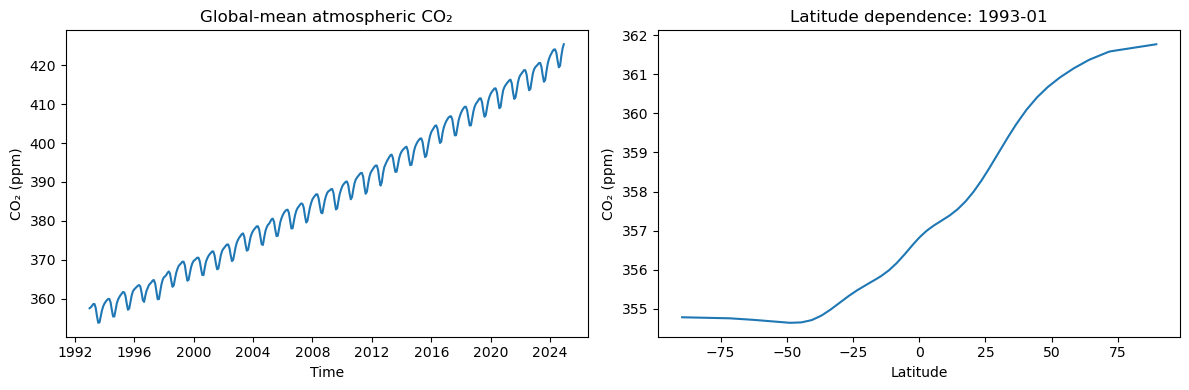

In [ ]:
co2 = ds["atm_co2_xco2"]

fig, axes = plt.subplots(1, 2, figsize=(12, 4))

# 1 Global mean time series
ax = axes[0]

ax.plot(ds.time, co2.mean(dim=["lat", "lon"]))
ax.set_xlabel("Time")
ax.set_ylabel("CO₂ (ppm)")
ax.set_title("Global-mean atmospheric CO₂")

# 2 Latitude dependence for one month
ax = axes[1]

sample = co2.isel(time=0)

ax.plot(ds.lat, sample.mean(dim="lon"))
ax.set_xlabel("Latitude")
ax.set_ylabel("CO₂ (ppm)")
ax.set_title(f"Latitude dependence: {str(ds.time.values[0])[:7]}")

plt.tight_layout()
plt.show()

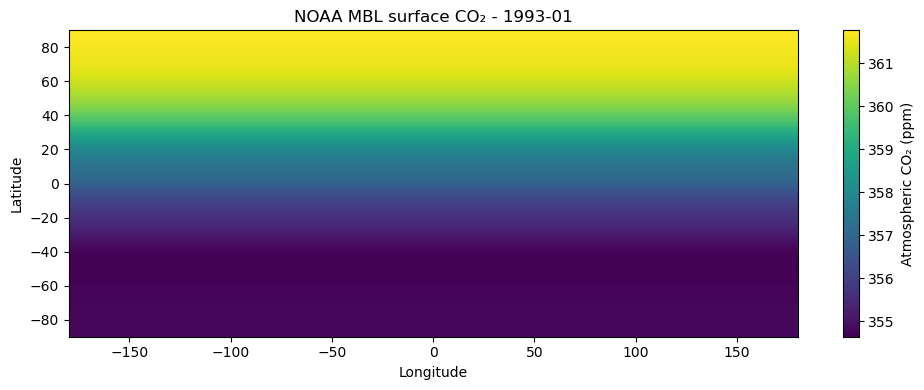

In [ ]:
fig, ax = plt.subplots(figsize=(10, 4))

ds["atm_co2_xco2"].isel(time=0).plot(
    ax=ax,
    cmap="viridis",
    cbar_kwargs={"label": "Atmospheric CO₂ (ppm)"}
)

ax.set_title(f"NOAA MBL surface CO₂ - {str(ds.time.values[0])[:7]}")
ax.set_xlabel("Longitude")
ax.set_ylabel("Latitude")

plt.tight_layout()
plt.show()

## 4. Save to Zarr

In [17]:
ds_chunked = ds.chunk({
    "time": time_chunk,
    "lat": lat_chunk,
    "lon": lon_chunk,
})

ds_chunked.to_zarr(
    store_out,
    mode="w",
    consolidated=True,
)

print(f"Written successfully to: {store_out}")

Written successfully to: /home/efs25/GitHub/irp-efs25/data/processed/satellite/noaa_gml_mbl_1x1_monthly.zarr


### Reopen and validate

In [ ]:
saved = xr.open_zarr(
    store_out,
    consolidated=True,
)

print(saved)

assert saved.sizes["time"] == 384
assert saved.sizes["lat"] == 180
assert saved.sizes["lon"] == 360

assert str(saved.time.values[0])[:10] == "1993-01-01"
assert str(saved.time.values[-1])[:10] == "2024-12-01"

assert saved["atm_co2_xco2"].attrs["units"] == "ppm"

assert bool(np.isfinite(saved["atm_co2_xco2"]).all())

# Confirm longitude uniformity
lon_range = saved["atm_co2_xco2"].max(dim="lon") - saved["atm_co2_xco2"].min(dim="lon")

assert np.allclose(lon_range.values, 0.0, atol=1e-6)

print("Longitude-uniformity check passed")

# Confirm latitude dependence
lat_range = saved["atm_co2_xco2"].max(dim="lat") - saved["atm_co2_xco2"].min(dim="lat")

print("Maximum latitude variation:", float(lat_range.max()))

assert float(lat_range.max()) > 0

print("Latitude-dependence check passed.")

print("First value:", float(saved["atm_co2_xco2"].isel(time=0, lat=90, lon=0)), "ppm")
print("Last value:", float(saved["atm_co2_xco2"].isel(time=-1, lat=90, lon=0)), "ppm")

<xarray.Dataset> Size: 100MB
Dimensions:       (time: 384, lat: 180, lon: 360)
Coordinates:
  * time          (time) datetime64[ns] 3kB 1993-01-01 1993-02-01 ... 2024-12-01
  * lat           (lat) float64 1kB -89.5 -88.5 -87.5 -86.5 ... 87.5 88.5 89.5
  * lon           (lon) float64 3kB -179.5 -178.5 -177.5 ... 177.5 178.5 179.5
Data variables:
    atm_co2_xco2  (time, lat, lon) float32 100MB dask.array<chunksize=(12, 90, 180), meta=np.ndarray>
Attributes:
    Conventions:           CF-1.8
    institution:           NOAA Global Monitoring Laboratory
    longitude_convention:  -180 to +180
    processing_note:       Latitude-dependent NOAA MBL surface CO2 values wer...
    title:                 NOAA GML MBL Surface CO2 on 1x1 degree monthly grid
Longitude-uniformity check passed.
Maximum latitude variation: 12.6480712890625
Latitude-dependence check passed.
First value: 356.8515319824219 ppm
Last value: 424.2048645019531 ppm
